In [1]:
%pip install -q pandas tensorflow numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


# Deep Learning for Function Estimation
### Amir, 2025, NUS SoC ACE

#### We'll try to estimate the quality of red wine samples based on their physical and chemical features
#### We compute and report the mean absolute error, MAE

In [2]:
# CNN version
# Regression Example With wine dataset ...
import pandas as pd
from pandas import read_csv
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense , Dropout
from tensorflow.keras.layers import Conv1D
from tensorflow.keras.layers import MaxPooling1D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt


In [3]:
# mounting the Google drive
# from google.colab import drive

# drive.mount('/content/drive')

# # Load the dataset
# fp = "/content/drive/My Drive/emeritus/2025/Module2-3/wine_r2_t_noheader.csv"
fp = "wine_r2_t_noheader.csv"

In [4]:

# load dataset to a Pandas dataframe
dataframe = read_csv(fp , header=None)
# copy only values to a numpy n dimensional array, ndarray
dataset = dataframe.values

# split into input (X) and output (Y) variables
X = dataset[:,0:11]
Y = dataset[:,11]

print(X.shape)
X = X.reshape(X.shape[0], X.shape[1], 1)
print(X.shape)


(1599, 11)
(1599, 11, 1)


In [5]:
print(type(dataset))
print(dataset.shape)
print(dataframe.describe())
print( dataframe.head() )

<class 'numpy.ndarray'>
(1599, 12)
                0            1            2            3            4   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean      8.319637     0.527821     0.270976     2.538806     0.087467   
std       1.741096     0.179060     0.194801     1.409928     0.047065   
min       4.600000     0.120000     0.000000     0.900000     0.012000   
25%       7.100000     0.390000     0.090000     1.900000     0.070000   
50%       7.900000     0.520000     0.260000     2.200000     0.079000   
75%       9.200000     0.640000     0.420000     2.600000     0.090000   
max      15.900000     1.580000     1.000000    15.500000     0.611000   

                5            6            7            8            9   \
count  1599.000000  1599.000000  1599.000000  1599.000000  1599.000000   
mean     15.874922    46.467792     0.996747     3.311113     0.658149   
std      10.460157    32.895324     0.001887     0.154386     0.169507   
mi

In [6]:
# define base model, a deep covolutional one
# structure comprisses 2 1d convolution layers with 16 and 12 filters, filters are 3x1
# then maxpooling for downsampling, a fully connected dense layer with 12 neurons
# Droput layer with 20% at the end
#
def baseline_model():
    # create model
    model = Sequential()
    model.add(Conv1D(16, 3, activation="relu", input_shape=(11,1)))
    model.add(Conv1D(12, 3, activation="relu"))
    model.add(Conv1D(16, 3, activation="relu"))
    model.add(Conv1D(12, 3, activation="relu"))
    model.add(MaxPooling1D())
    model.add(Flatten())
    model.add(Dense(12, input_dim=8, kernel_initializer='normal', activation='relu'))
    model.add(Dense(12, input_dim=8, kernel_initializer='normal', activation='relu'))
    model.add( Dropout(0.2) )
    model.add(Dense(1, kernel_initializer='normal'))
    # Compile model
    model.compile(loss='mean_squared_error', optimizer='adam')
    return model


In [7]:
# splitting the train and test subsets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [8]:
# training the model for 900 epochs and testing the trained model with the training data
# we report the training error
estimator = baseline_model()
estimator.fit(X_train, Y_train, epochs=900, verbose=2)
prediction = estimator.predict(X_train)

train_error =  np.abs(Y_train - prediction)
mean_error = np.mean(train_error)
min_error = np.min(train_error)
max_error = np.max(train_error)
std_error = np.std(train_error)
# print('\nTraining results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

print('\nTraining results:')
print('MAE =', mean_error)
print('Min error =', min_error)
print('Max error =', max_error)
print('STD error =', std_error)

Epoch 1/900


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


40/40 - 0s - 11ms/step - loss: 30.6004
Epoch 2/900
40/40 - 0s - 982us/step - loss: 14.3351
Epoch 3/900
40/40 - 0s - 813us/step - loss: 11.9416
Epoch 4/900
40/40 - 0s - 750us/step - loss: 11.1561
Epoch 5/900
40/40 - 0s - 779us/step - loss: 10.4372
Epoch 6/900
40/40 - 0s - 769us/step - loss: 9.2060
Epoch 7/900
40/40 - 0s - 780us/step - loss: 7.4902
Epoch 8/900
40/40 - 0s - 787us/step - loss: 5.1128
Epoch 9/900
40/40 - 0s - 772us/step - loss: 4.0978
Epoch 10/900
40/40 - 0s - 771us/step - loss: 3.1446
Epoch 11/900
40/40 - 0s - 793us/step - loss: 3.3727
Epoch 12/900
40/40 - 0s - 760us/step - loss: 3.1911
Epoch 13/900
40/40 - 0s - 756us/step - loss: 3.0653
Epoch 14/900
40/40 - 0s - 834us/step - loss: 3.0002
Epoch 15/900
40/40 - 0s - 785us/step - loss: 2.8101
Epoch 16/900
40/40 - 0s - 791us/step - loss: 3.0169
Epoch 17/900
40/40 - 0s - 795us/step - loss: 3.2592
Epoch 18/900
40/40 - 0s - 769us/step - loss: 2.7982
Epoch 19/900
40/40 - 0s - 774us/step - loss: 3.0816
Epoch 20/900
40/40 - 0s - 764

In [9]:
# showing the real and predicted quality scores for the training data
df = pd.DataFrame({'Actual': Y_train, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

      Actual  Predicted
1254     6.0   5.705120
1255     6.0   5.343198
1256     5.0   5.464569
1257     5.0   5.358574
1258     6.0   5.342485
1259     5.0   5.212892
1260     5.0   5.522943
1261     5.0   5.619195
1262     6.0   5.688338
1263     6.0   6.450404
1264     5.0   4.918251
1265     5.0   5.700840
1266     5.0   5.347154
1267     4.0   4.580472
1268     5.0   5.519317
1269     6.0   5.738601
1270     6.0   5.774672
1271     6.0   5.559210
1272     6.0   5.594105
1273     5.0   5.342485
1274     5.0   5.342485
1275     5.0   4.920124
1276     6.0   5.342485
1277     6.0   6.029694
1278     5.0   5.145004


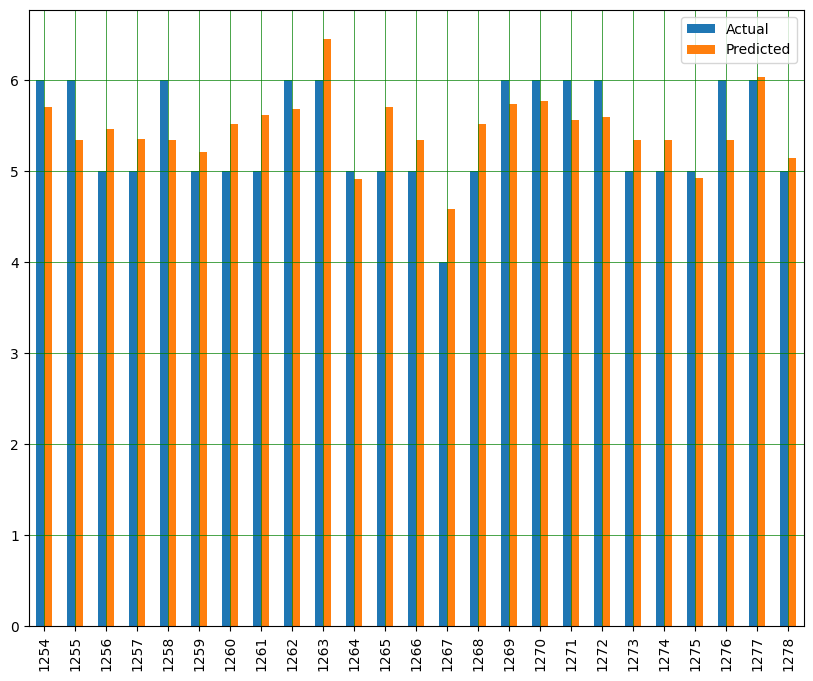

In [10]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

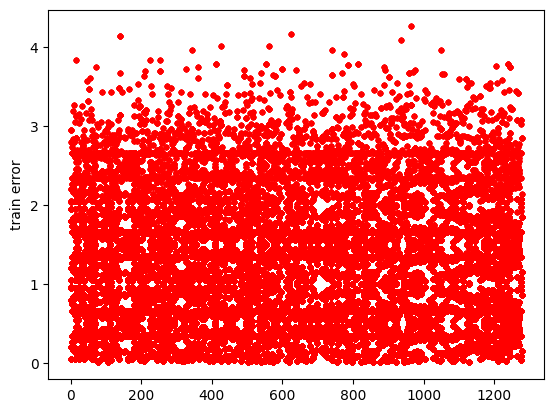

In [11]:
plt.plot(train_error,'r.')
plt.ylabel('train error')
plt.show()

In [12]:
# testing the model with the test data
prediction = estimator.predict(X_test)

test_error =  np.abs(Y_test - prediction)
mean_error = np.mean(test_error)
min_error = np.min(test_error)
max_error = np.max(test_error)
std_error = np.std(test_error)
print('\nTesting results:\nmean=',mean_error,'\nmin=',min_error,'\nmax=',max_error,'\nstd=',std_error)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 829us/step

Testing results:
mean= 0.7107194284256547 
min= 0.00086212158203125 
max= 4.020882606506348 
std= 0.5332163912513216


In [13]:
# and showing the results
df = pd.DataFrame({'Actual': Y_test, 'Predicted': prediction.ravel() })
df1 = df.tail(25)
print(df1)

     Actual  Predicted
295     6.0   6.041007
296     6.0   5.743663
297     5.0   5.942126
298     6.0   5.118911
299     5.0   5.378296
300     6.0   5.827726
301     5.0   4.903560
302     6.0   5.637041
303     6.0   5.986326
304     6.0   6.028494
305     6.0   5.907568
306     5.0   5.848870
307     5.0   5.657988
308     6.0   5.342485
309     5.0   5.796370
310     5.0   5.348710
311     6.0   6.180751
312     5.0   5.544060
313     5.0   5.342485
314     5.0   5.619125
315     6.0   6.090072
316     4.0   6.113965
317     5.0   6.479552
318     4.0   4.442764
319     6.0   6.280565


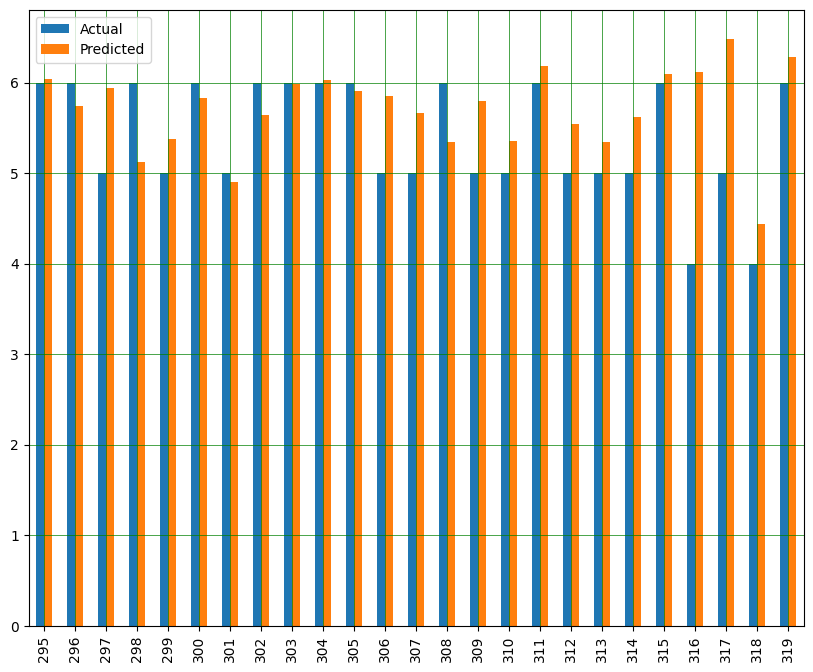

In [14]:
df1.plot(kind='bar',figsize=(10,8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='minor', linestyle=':', linewidth='0.5', color='black')
plt.show()

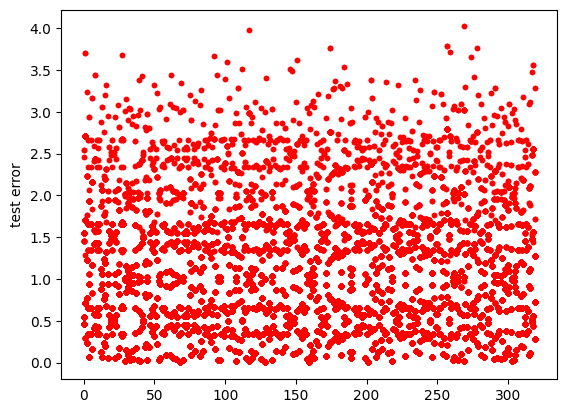

In [15]:
plt.plot(test_error,'r.')
plt.ylabel('test error')
plt.show()

##  Practices
1. train the model for 1400 epochs. what are the training and testing MAE?
2. repeat that with 6000 training epochs. what are the training and testing MAE?
3. move back to 900 training epochs. add two convolutional and one dense layer with the same features of the layers used. what are the training and testing MAE?
4. go for 6000 training epochs. Do you feel any overfitting?
5. set back everything to the original setting, then try to normalize the training and testing features and outputs using standard_scaler. Then see if anything gets better or not. You may use insttructions like what you can see in the next cell.  

#### points:
- use GPU as your runtime type
- if the notebook overflows, change the verbose to 0, e.g. verbose=0 in the training cell.

In [16]:
'''
# normalization
from sklearn.preprocessing import StandardScaler

# Create scalers
scaler_X = StandardScaler()
scaler_y = StandardScaler()

# Standardize X_train and X_test
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)
y_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed
y_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))
'''

'\n# normalization\nfrom sklearn.preprocessing import StandardScaler\n\n# Create scalers\nscaler_X = StandardScaler()\nscaler_y = StandardScaler()\n\n# Standardize X_train and X_test\nX_train_scaled = scaler_X.fit_transform(X_train)\nX_test_scaled = scaler_X.transform(X_test)\n\n# Standardize Y_train and Y_test (only if y is continuous, e.g., in regression)\ny_train_scaled = scaler_y.fit_transform(Y_train.reshape(-1, 1))  # Reshape if needed\ny_test_scaled = scaler_y.transform(Y_test.reshape(-1, 1))\n'